# GPU Assignment II
## HW4.a BERT Fine Tuning, vLLM Inference, and HW4.5 GPU Engineering

SID4 = 2046  
SEED = 2046  
SLICE = 46  
HP_ID = 0  
CLS_A = 6  
CLS_B = 3

Run top to bottom in Google Colab with a GPU runtime. Part C requires an actual instructor designated two GPU system; the notebook will not fabricate those measurements.

In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("VRAM GB:", torch.cuda.get_device_properties(0).total_memory / 1024**3)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)

## 0. Install dependencies

In [1]:
!pip -q install -U "transformers>=4.45" datasets accelerate scikit-learn pandas matplotlib psutil pynvml bitsandbytes

## 1. Imports, constants, reproducibility, and hardware capture

In [2]:
import os, gc, json, math, time, random, platform, shutil
from pathlib import Path
from contextlib import nullcontext
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader, TensorDataset
from datasets import load_dataset
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support, ConfusionMatrixDisplay
from transformers import BertTokenizer, BertForSequenceClassification, AutoTokenizer, AutoModelForCausalLM, pipeline
SID4=2046; SEED=2046; SLICE=46; HP_ID=0; CLS_A=6; CLS_B=3
DATASET_NAME='tweet_eval'; DATASET_CONFIG='sentiment'; BERT_MODEL='bert-base-uncased'; VLLM_MODEL='Qwen/Qwen2.5-0.5B-Instruct'
MAX_ROWS=5000; MAX_LENGTH=128; BASE_BATCH_SIZE=16; BASE_EPOCHS=4; BASE_LR=2e-5; WEIGHT_DECAY=0.01
OUT=Path('/content/gpu_assignment_outputs'); OUT.mkdir(parents=True,exist_ok=True)
def seed_all(seed=SEED):
 random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_all(); DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu'); GPU_COUNT=torch.cuda.device_count()
hardware={'sid4':SID4,'seed':SEED,'slice':SLICE,'hp_id':HP_ID,'cls_a':CLS_A,'cls_b':CLS_B,'python':platform.python_version(),'torch':torch.__version__,'cuda_available':torch.cuda.is_available(),'cuda_version':torch.version.cuda,'gpu_count':GPU_COUNT,'gpus':[{'index':i,'name':torch.cuda.get_device_name(i),'total_memory_gb':round(torch.cuda.get_device_properties(i).total_memory/1024**3,3)} for i in range(GPU_COUNT)]}
print(json.dumps(hardware,indent=2)); json.dump(hardware,open(OUT/'hardware.json','w'),indent=2)
assert torch.cuda.is_available(),'Select a GPU runtime in Colab before continuing.'

/opt/conda/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


{
  "sid4": 2046,
  "seed": 2046,
  "slice": 46,
  "hp_id": 0,
  "cls_a": 6,
  "cls_b": 3,
  "python": "3.11.13",
  "torch": "2.7.1+cu128",
  "cuda_available": true,
  "cuda_version": "12.8",
  "gpu_count": 1,
  "gpus": [
    {
      "index": 0,
      "name": "NVIDIA GeForce RTX 5090",
      "total_memory_gb": 31.842
    }
  ]
}


## 2. Load Hugging Face TweetEval sentiment and construct the assigned consecutive subset

In [4]:
raw = load_dataset(
    "cardiffnlp/tweet_eval",
    "sentiment"
)

source = raw["train"]

start = SLICE
stop = min(SLICE + MAX_ROWS, len(source))

working = source.select(range(start, stop))

texts = np.array(
    working["text"],
    dtype=object
)

labels = np.array(
    working["label"],
    dtype=np.int64
)

label_names = source.features["label"].names
NUM_LABELS = len(label_names)

print("Dataset:", "cardiffnlp/tweet_eval")
print("Configuration:", "sentiment")
print("Exact working row range:", start, "to", stop - 1)
print("Rows:", len(working))
print("Labels:", dict(enumerate(label_names)))

pd.DataFrame(
    {
        "dataset": ["cardiffnlp/tweet_eval"],
        "config": ["sentiment"],
        "start_row": [start],
        "end_row": [stop - 1],
        "n_rows": [len(working)],
    }
).to_csv(
    OUT / "dataset_range.csv",
    index=False
)

Generating validation split: 100%|██████████| 2000/2000 [00:00<00:00, 893831.43 examples/s]

Dataset: cardiffnlp/tweet_eval
Configuration: sentiment
Exact working row range: 46 to 5045
Rows: 5000
Labels: {0: 'negative', 1: 'neutral', 2: 'positive'}


## 3. Required 70 percent train, 15 percent validation, 15 percent test split using SEED 2046

In [5]:
idx=np.arange(len(texts)); train_idx,temp_idx=train_test_split(idx,test_size=.30,random_state=SEED,stratify=labels); val_idx,test_idx=train_test_split(temp_idx,test_size=.50,random_state=SEED,stratify=labels[temp_idx])
split_indices={'source_start':int(start),'source_end':int(stop-1),'train':train_idx.tolist(),'validation':val_idx.tolist(),'test':test_idx.tolist()}; json.dump(split_indices,open(OUT/'split_indices.json','w'),indent=2)
print('Train',len(train_idx),'Validation',len(val_idx),'Test',len(test_idx))

Train 3500 Validation 750 Test 750


## 4. BERT tokenization and tensor datasets

In [6]:
bert_tokenizer=BertTokenizer.from_pretrained(BERT_MODEL)
def tokenize_indices(indices):
 e=bert_tokenizer(texts[indices].tolist(),padding='max_length',truncation=True,max_length=MAX_LENGTH,return_tensors='pt'); return TensorDataset(e['input_ids'],e['attention_mask'],torch.tensor(labels[indices],dtype=torch.long))
train_ds=tokenize_indices(train_idx); val_ds=tokenize_indices(val_idx); test_ds=tokenize_indices(test_idx)
print(len(train_ds),len(val_ds),len(test_ds))

3500 750 750


## 5. Training utilities

In [7]:
def make_loaders(batch_size):
 g=torch.Generator().manual_seed(SEED); return (DataLoader(train_ds,batch_size=batch_size,shuffle=True,generator=g,pin_memory=True),DataLoader(val_ds,batch_size=batch_size,shuffle=False,pin_memory=True),DataLoader(test_ds,batch_size=batch_size,shuffle=False,pin_memory=True))
@torch.no_grad()
def evaluate_classifier(model,loader):
 model.eval(); total_loss=0.; total=0; preds=[]; targets=[]
 for ids,mask,y in loader:
  ids,mask,y=ids.to(DEVICE),mask.to(DEVICE),y.to(DEVICE); o=model(input_ids=ids,attention_mask=mask,labels=y); n=y.size(0); total_loss+=o.loss.item()*n; total+=n; preds+=o.logits.argmax(-1).cpu().tolist(); targets+=y.cpu().tolist()
 return {'loss':total_loss/total,'accuracy':accuracy_score(targets,preds),'predictions':preds,'targets':targets}
def fresh_bert(): seed_all(); return BertForSequenceClassification.from_pretrained(BERT_MODEL,num_labels=NUM_LABELS).to(DEVICE)
def train_epoch(model,loader,optimizer,scaler=None,use_amp=False,accumulation_steps=1):
 model.train(); total_loss=0.; total=0; optimizer.zero_grad(set_to_none=True)
 for step,(ids,mask,y) in enumerate(loader,1):
  ids,mask,y=ids.to(DEVICE),mask.to(DEVICE),y.to(DEVICE); ctx=torch.autocast('cuda',dtype=torch.float16) if use_amp else nullcontext()
  with ctx: o=model(input_ids=ids,attention_mask=mask,labels=y); loss=o.loss/accumulation_steps
  if use_amp: scaler.scale(loss).backward()
  else: loss.backward()
  if step%accumulation_steps==0 or step==len(loader):
   if use_amp: scaler.step(optimizer); scaler.update()
   else: optimizer.step()
   optimizer.zero_grad(set_to_none=True)
  n=y.size(0); total_loss+=loss.item()*accumulation_steps*n; total+=n
 return total_loss/total
def cleanup():
 gc.collect(); torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

# HW4.a
## 6. Baseline BERT fine tune and required memory/time baseline

In [8]:
cleanup(); seed_all(); train_loader,val_loader,test_loader=make_loaders(BASE_BATCH_SIZE); model=fresh_bert(); optimizer=torch.optim.AdamW(model.parameters(),lr=BASE_LR,weight_decay=WEIGHT_DECAY)
torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize(); t0=time.perf_counter(); history=[]; best_val_acc=-1.; best_val_loss=float('inf'); best_epoch=None; best_path=OUT/'bert_best'
for epoch in range(1,BASE_EPOCHS+1):
 torch.cuda.synchronize(); e0=time.perf_counter(); train_loss=train_epoch(model,train_loader,optimizer); v=evaluate_classifier(model,val_loader); torch.cuda.synchronize(); es=time.perf_counter()-e0; row={'epoch':epoch,'train_loss':train_loss,'val_loss':v['loss'],'val_accuracy':v['accuracy'],'epoch_seconds':es}; history.append(row); print(row)
 improved=v['accuracy']>best_val_acc or (v['accuracy']==best_val_acc and v['loss']<best_val_loss)
 if improved: best_val_acc=v['accuracy']; best_val_loss=v['loss']; best_epoch=epoch; model.save_pretrained(best_path); bert_tokenizer.save_pretrained(best_path)
torch.cuda.synchronize(); training_seconds=time.perf_counter()-t0; peak_memory_gb=torch.cuda.max_memory_allocated()/1024**3; history_df=pd.DataFrame(history); history_df.to_csv(OUT/'hw4a_training_history.csv',index=False)
baseline_summary={'batch_size':BASE_BATCH_SIZE,'epochs':BASE_EPOCHS,'learning_rate':BASE_LR,'weight_decay':WEIGHT_DECAY,'best_epoch':best_epoch,'best_val_accuracy':best_val_acc,'best_val_loss':best_val_loss,'peak_memory_gb':peak_memory_gb,'training_seconds':training_seconds}; json.dump(baseline_summary,open(OUT/'hw4a_baseline_summary.json','w'),indent=2)
print(baseline_summary)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 23344.70it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpo

{'epoch': 1, 'train_loss': 0.8455282326425825, 'val_loss': 0.7182404114405314, 'val_accuracy': 0.6586666666666666, 'epoch_seconds': 12.689400572000068}


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.66it/s]


{'epoch': 2, 'train_loss': 0.5424941726071494, 'val_loss': 0.7447207269668579, 'val_accuracy': 0.6586666666666666, 'epoch_seconds': 11.88798464599995}
{'epoch': 3, 'train_loss': 0.2952959340299879, 'val_loss': 0.9417916994094848, 'val_accuracy': 0.6666666666666666, 'epoch_seconds': 11.839930698999979}


Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  1.64it/s]


{'epoch': 4, 'train_loss': 0.1450113518663815, 'val_loss': 1.1257300930023193, 'val_accuracy': 0.6653333333333333, 'epoch_seconds': 11.851847287000055}
{'batch_size': 16, 'epochs': 4, 'learning_rate': 2e-05, 'weight_decay': 0.01, 'best_epoch': 3, 'best_val_accuracy': 0.6666666666666666, 'best_val_loss': 0.9417916994094848, 'peak_memory_gb': 2.477545738220215, 'training_seconds': 49.511319230000026}


## 7. Training curves and epoch where validation stopped improving

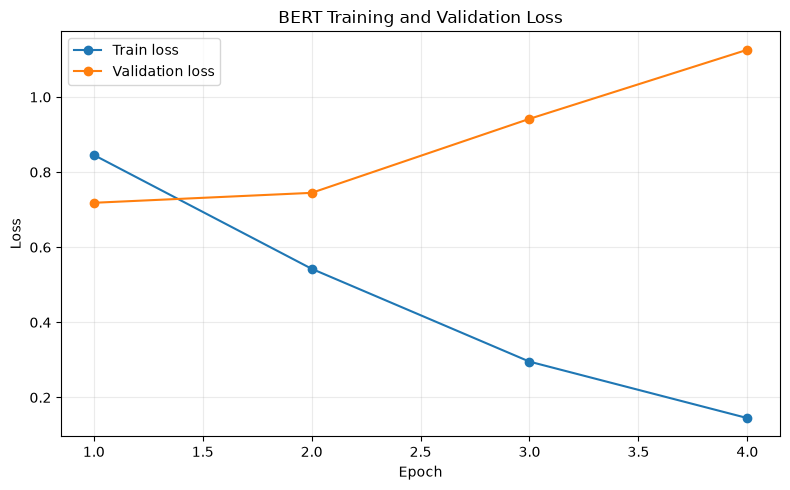

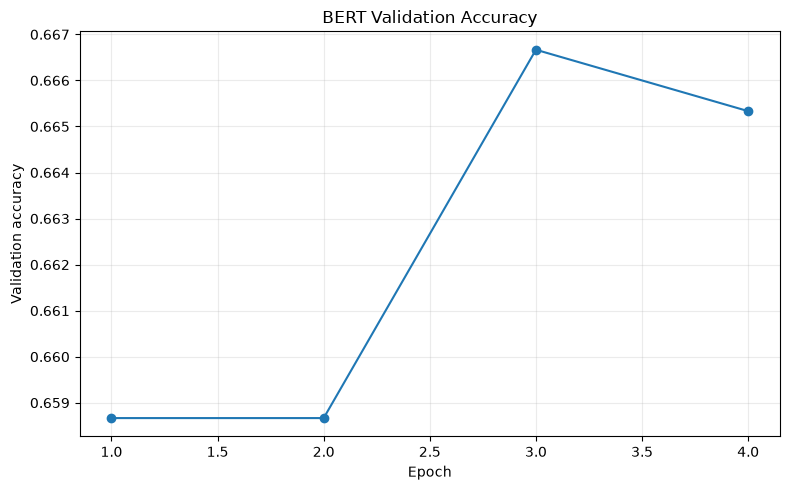

Validation stopped improving after epoch 3
Cost after best epoch 11.851847287000055 seconds


In [9]:
plt.figure(figsize=(8,5)); plt.plot(history_df.epoch,history_df.train_loss,marker='o',label='Train loss'); plt.plot(history_df.epoch,history_df.val_loss,marker='o',label='Validation loss'); plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.title('BERT Training and Validation Loss'); plt.legend(); plt.grid(alpha=.25); plt.tight_layout(); plt.savefig(OUT/'bert_loss_curve.png',dpi=200); plt.show()
plt.figure(figsize=(8,5)); plt.plot(history_df.epoch,history_df.val_accuracy,marker='o'); plt.xlabel('Epoch'); plt.ylabel('Validation accuracy'); plt.title('BERT Validation Accuracy'); plt.grid(alpha=.25); plt.tight_layout(); plt.savefig(OUT/'bert_val_accuracy_curve.png',dpi=200); plt.show()
stop_epoch=int(history_df.loc[history_df.val_accuracy.idxmax(),'epoch']); extra_seconds=history_df.loc[history_df.epoch>stop_epoch,'epoch_seconds'].sum() if stop_epoch<BASE_EPOCHS else 0.; print('Validation stopped improving after epoch',stop_epoch); print('Cost after best epoch',extra_seconds,'seconds')

## 8. Reload selected checkpoint and evaluate test set

In [10]:
del model; cleanup(); best_model=BertForSequenceClassification.from_pretrained(best_path).to(DEVICE); test_metrics=evaluate_classifier(best_model,test_loader); print('Test loss',test_metrics['loss'],'Test accuracy',test_metrics['accuracy'])

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 10677.26it/s]


Test loss 0.893917372862498 Test accuracy 0.6933333333333334


## 9. Confusion matrix, per class precision/recall, worst class, five errors

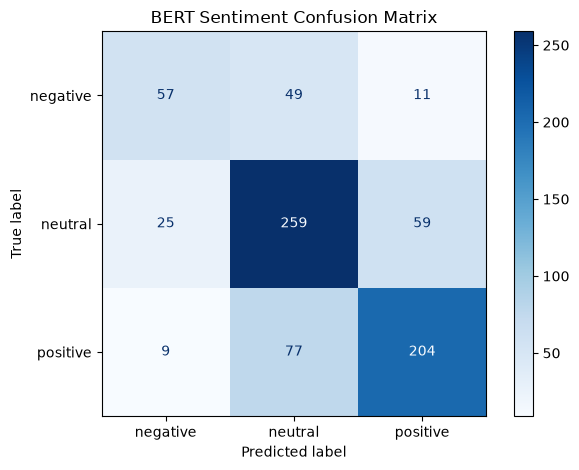

,class_id,class_name,precision,recall,f1,support
0,0,negative,0.626374,0.487179,0.548077,117
1,1,neutral,0.672727,0.755102,0.711538,343
2,2,positive,0.744526,0.703448,0.723404,290


Worst class 0 negative


,example,text,true_class,predicted_class,diagnosis
0,1,it's July 45 and there is still no news of the...,negative,neutral,Model confused this with neutral; inspect ambi...
1,2,"""By Joe Hemba DAMATURU, Nigeria, July 10 (Reut...",negative,neutral,Model confused this with neutral; inspect ambi...
2,3,it's August 15 and Frank Ocean still hasn't dr...,negative,neutral,Model confused this with neutral; inspect ambi...
3,4,WTH Apple? 1st I go to the apple and there is ...,negative,neutral,Model confused this with neutral; inspect ambi...
4,5,"""The Bucks' John Henson is hit at the knee by ...",negative,neutral,Model confused this with neutral; inspect ambi...


In [11]:
y_true=np.array(test_metrics['targets']); y_pred=np.array(test_metrics['predictions']); cm=confusion_matrix(y_true,y_pred,labels=np.arange(NUM_LABELS)); disp=ConfusionMatrixDisplay(cm,display_labels=label_names); disp.plot(cmap='Blues',values_format='d'); plt.title('BERT Sentiment Confusion Matrix'); plt.tight_layout(); plt.savefig(OUT/'bert_confusion_matrix.png',dpi=200); plt.show()
p,r,f1,s=precision_recall_fscore_support(y_true,y_pred,labels=np.arange(NUM_LABELS),zero_division=0); class_metrics=pd.DataFrame({'class_id':np.arange(NUM_LABELS),'class_name':label_names,'precision':p,'recall':r,'f1':f1,'support':s}); display(class_metrics); class_metrics.to_csv(OUT/'bert_per_class_metrics.csv',index=False); worst_class=int(class_metrics.loc[class_metrics.f1.idxmin(),'class_id']); print('Worst class',worst_class,label_names[worst_class])
positions=np.where((y_true==worst_class)&(y_pred!=y_true))[0][:5]; rows=[]
for rank,pos in enumerate(positions,1):
 li=int(test_idx[pos]); pred=int(y_pred[pos]); true=int(y_true[pos]); rows.append({'example':rank,'text':str(texts[li]),'true_class':label_names[true],'predicted_class':label_names[pred],'diagnosis':f'Model confused this with {label_names[pred]}; inspect ambiguity, negation, sarcasm, or limited tweet context.'})
misclassified_df=pd.DataFrame(rows); display(misclassified_df); misclassified_df.to_csv(OUT/'five_worst_class_misclassifications.csv',index=False)

## 10. Save, reload, and custom BERT inference

In [12]:
custom_texts=['I absolutely loved this. It made my day.','This was disappointing and frustrating.','It was fine, nothing special either way.']; reloaded_model=BertForSequenceClassification.from_pretrained(best_path).to(DEVICE); reloaded_tokenizer=BertTokenizer.from_pretrained(best_path); reloaded_model.eval()
for text in custom_texts:
 e=reloaded_tokenizer(text,return_tensors='pt',truncation=True,max_length=MAX_LENGTH); e={k:v.to(DEVICE) for k,v in e.items()};
 with torch.no_grad(): logits=reloaded_model(**e).logits
 pred=int(logits.argmax(-1).item()); print(text,'=>',label_names[pred])

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 10381.30it/s]

I absolutely loved this. It made my day. => positive
This was disappointing and frustrating. => negative
It was fine, nothing special either way. => positive


# HW4.a vLLM serving
## 11. Plain Hugging Face pipeline baseline, batch 1

In [13]:
cleanup(); SERVING_PROMPTS=['In one sentence, explain why GPU batching can improve throughput.','Give two practical uses of sentiment analysis.','Explain mixed precision in one short sentence.','What is gradient checkpointing?','Why can latency increase as batch size grows?','Define GPU memory bandwidth.','What does p95 latency mean?','Explain data parallel training briefly.']*4; MAX_NEW_TOKENS=48
hf_tokenizer=AutoTokenizer.from_pretrained(VLLM_MODEL); hf_model=AutoModelForCausalLM.from_pretrained(VLLM_MODEL,torch_dtype=torch.float16,device_map='auto'); hf_tokenizer.pad_token=hf_tokenizer.pad_token or hf_tokenizer.eos_token; hf_pipe=pipeline('text-generation',model=hf_model,tokenizer=hf_tokenizer)
def pct(v,q): return float(np.percentile(np.array(v,float),q))
lat=[]; toks=0; torch.cuda.synchronize(); t0=time.perf_counter()
for prompt in SERVING_PROMPTS:
 torch.cuda.synchronize(); r0=time.perf_counter(); out=hf_pipe(prompt,max_new_tokens=MAX_NEW_TOKENS,do_sample=False,return_full_text=False)[0]['generated_text']; torch.cuda.synchronize(); lat.append((time.perf_counter()-r0)*1000); toks+=len(hf_tokenizer.encode(out,add_special_tokens=False))
total=time.perf_counter()-t0; hf_result={'configuration':'HF pipeline, batch 1','batch_size':1,'tokens_per_second':toks/total,'p50_latency_ms':pct(lat,50),'p95_latency_ms':pct(lat,95),'total_seconds':total}; print(hf_result); del hf_pipe,hf_model,hf_tokenizer; cleanup()

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 290/290 [00:00<00:00, 1711.77it/s]
[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


{'configuration': 'HF pipeline, batch 1', 'batch_size': 1, 'tokens_per_second': 75.31482768145543, 'p50_latency_ms': 599.7923109999874, 'p95_latency_ms': 874.96836635014, 'total_seconds': 20.394390418000057}


## 12. Install vLLM

In [14]:
!pip -q install -U vllm

In [17]:
import torch
import importlib.metadata

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("vLLM:", importlib.metadata.version("vllm"))

PyTorch: 2.7.1+cu128
CUDA: 12.8
vLLM: 0.33.0


In [19]:
from pathlib import Path
import shutil

source = Path("/content/gpu_assignment_outputs")
destination = Path("/app/gpu_assignment_outputs")

if destination.exists():
    shutil.rmtree(destination)

shutil.copytree(source, destination)

print("Saved outputs to:", destination)

for file in sorted(destination.iterdir()):
    print(file.name)

Saved outputs to: /app/gpu_assignment_outputs
bert_best
bert_confusion_matrix.png
bert_loss_curve.png
bert_per_class_metrics.csv
bert_val_accuracy_curve.png
dataset_range.csv
five_worst_class_misclassifications.csv
hardware.json
hw4a_baseline_summary.json
hw4a_training_history.csv
split_indices.json


In [20]:
import pandas as pd

hf_result = {
    "configuration": "HF pipeline, batch 1",
    "batch_size": 1,
    "tokens_per_second": 75.31482768145543,
    "p50_latency_ms": 599.7923109999874,
    "p95_latency_ms": 874.96836635014,
    "total_seconds": 20.394390418000057,
}

pd.DataFrame([hf_result]).to_csv(
    "/app/gpu_assignment_outputs/hf_pipeline_baseline.csv",
    index=False,
)

print("HF baseline saved.")

HF baseline saved.


In [21]:
!pip uninstall -y vllm
!pip install -U vllm --extra-index-url https://download.pytorch.org/whl/cu128

Found existing installation: vllm 0.33.0
Uninstalling vllm-0.33.0:
  Successfully uninstalled vllm-0.33.0
Looking in indexes: https://pypi.org/simple, https://download.pytorch.org/whl/cu128
  Using cached vllm-0.33.0-cp38-abi3-manylinux_2_28_x86_64.whl.metadata (11 kB)
Using cached vllm-0.33.0-cp38-abi3-manylinux_2_28_x86_64.whl (336.4 MB)


In [2]:
import torch
import importlib.metadata

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
print("GPU:", torch.cuda.get_device_name(0))
print("vLLM:", importlib.metadata.version("vllm"))

PyTorch: 2.14.0+cu130
CUDA: 13.0
CUDA available: True
GPU: NVIDIA GeForce RTX 5090
vLLM: 0.33.0


In [4]:
import gc
import torch

from transformers import AutoTokenizer
from vllm import LLM, SamplingParams

VLLM_MODEL = "Qwen/Qwen2.5-0.5B-Instruct"
MAX_NEW_TOKENS = 48

gc.collect()
torch.cuda.empty_cache()

sampling_params = SamplingParams(
    temperature=0.0,
    max_tokens=MAX_NEW_TOKENS
)

llm = LLM(
    model=VLLM_MODEL,
    dtype="float16",
    gpu_memory_utilization=0.80,
    max_model_len=2048
)

vllm_tokenizer = AutoTokenizer.from_pretrained(VLLM_MODEL)

print("vLLM model loaded successfully")
print("Model:", VLLM_MODEL)
print("GPU:", torch.cuda.get_device_name(0))

(MainProcess pid=350) INFO 11-03 05:05:26 [startup.py:96] non-default args: {'dtype': 'float16', 'max_model_len': 2048, 'gpu_memory_utilization': 0.8, 'disable_log_stats': True, 'model': 'Qwen/Qwen2.5-0.5B-Instruct'}
(MainProcess pid=350) INFO 11-03 05:05:35 [model.py:744] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=350) WARNING 11-03 05:05:35 [model.py:2516] Casting torch.bfloat16 to torch.float16.
(MainProcess pid=350) INFO 11-03 05:05:35 [model.py:2170] Using max model len 2048
(MainProcess pid=350) INFO 11-03 05:05:35 [scheduler.py:310] Chunked prefill is enabled with max_num_batched_tokens=8192.


(MainProcess pid=350) INFO 11-03 05:05:35 [kernel.py:480] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])


Fetching 9 files: 100%|██████████| 9/9 [00:00<00:00, 79.50it/s]


(MainProcess pid=350) WARNING 11-03 05:05:36 [system_utils.py:154] We must use the `spawn` multiprocessing start method. Overriding VLLM_WORKER_MULTIPROC_METHOD to 'spawn'. See https://docs.vllm.ai/en/latest/usage/troubleshooting.html#python-multiprocessing for more information. Reasons: CUDA is initialized; WSL is detected and NVML is not compatible with fork


/opt/conda/lib/python3.11/site-packages/torch/cuda/__init__.py:68: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]
W1103 05:05:38.914000 527 site-packages/torch/_opaque_base.py:6] torch._opaque_base is deprecated, use torch._custom_class_base instead
W1103 05:05:38.914000 527 site-packages/torch/_library/opaque_object.py:288] register_opaque_type is deprecated, use register_custom_class instead
W1103 05:05:38.914000 527 site-packages/torch/_library/opaque_object.py:211] typ='value' is deprecated, use typ='constant' instead


(EngineCore pid=527) INFO 11-03 05:05:41 [core.py:139] Initializing a V1 LLM engine (v0.33.0) with config: model='Qwen/Qwen2.5-0.5B-Instruct', speculative_config=None, tokenizer='Qwen/Qwen2.5-0.5B-Instruct', skip_tokenizer_init=False, tokenizer_mode=auto, revision=main, tokenizer_revision=main, trust_remote_code=False, dtype=torch.float16, max_seq_len=2048, download_dir=None, load_format=auto, tensor_parallel_size=1, pipeline_parallel_size=1, data_parallel_size=1, decode_context_parallel_size=1, dcp_comm_backend=ag_rs, disable_custom_all_reduce=False, quantization=None, quantization_config=None, enforce_eager=False, aux_output_config=AuxOutputConfig(enable_return_routed_experts=False, max_bytes=None), kv_cache_dtype=auto, device_config=cuda, structured_outputs_config=StructuredOutputsConfig(backend='auto', disable_any_whitespace=False, disable_additional_properties=False, reasoning_parser='', reasoning_parser_plugin='', enable_in_reasoning=False), observability_config=ObservabilityConf

... (8 outputs left out)

Capturing CUDA graphs (FULL): 100%|██████████| 35/35 [00:50<00:00,  1.44s/it]


(EngineCore pid=527) INFO 11-03 05:08:28 [model_runner.py:1163] Graph capturing finished in 53 secs, took 0.10 GiB
(EngineCore pid=527) INFO 11-03 05:08:28 [gpu_worker.py:1003] CUDA graph pool memory: 0.1 GiB (actual), 0.26 GiB (estimated), difference: 0.16 GiB (158.2%).
(EngineCore pid=527) INFO 11-03 05:08:28 [gpu_worker.py:1066] Free memory on device (30.05/31.84 GiB) on startup. Desired GPU memory utilization is (0.8, 25.47 GiB). Actual usage is 1.16 GiB for consumed memory (weights + non-torch), 0.79 GiB for peak activation, and 0.1 GiB for CUDAGraph memory. Replace gpu_memory_utilization config with `--kv-cache-memory=24985714688` (23.27 GiB) to fit into requested memory, or `--kv-cache-memory=29901176832` (27.85 GiB) to fully utilize gpu memory. Current kv cache memory in use is 23.52 GiB.
(EngineCore pid=527) INFO 11-03 05:08:29 [jit_monitor.py:84] Kernel JIT monitor activated; monitored JIT compilations during inference will use mode=warn.
(EngineCore pid=527) INFO 11-03 05:08

Fetching 9 files: 100%|██████████| 9/9 [00:00<00:00, 3259.82it/s]


(EngineCore pid=527) INFO 11-03 05:08:30 [kernel.py:480] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])
(MainProcess pid=350) INFO 11-03 05:08:30 [hf.py:736] Detected the chat template content format to be 'string'. You can set `--chat-template-content-format` to override this.
vLLM model loaded successfully
Model: Qwen/Qwen2.5-0.5B-Instruct
GPU: NVIDIA GeForce RTX 5090


In [8]:
import time
import numpy as np
import pandas as pd
from pathlib import Path

OUT = Path("/app/gpu_assignment_outputs")
OUT.mkdir(parents=True, exist_ok=True)

SERVING_PROMPTS = [
    "In one sentence, explain why GPU batching can improve throughput.",
    "Give two practical uses of sentiment analysis.",
    "Explain mixed precision in one short sentence.",
    "What is gradient checkpointing?",
    "Why can latency increase as batch size grows?",
    "Define GPU memory bandwidth.",
    "What does p95 latency mean?",
    "Explain data parallel training briefly.",
] * 4

hf_result = {
    "configuration": "HF pipeline, batch 1",
    "batch_size": 1,
    "tokens_per_second": 75.31482768145543,
    "p50_latency_ms": 599.7923109999874,
    "p95_latency_ms": 874.96836635014,
    "total_seconds": 20.394390418000057,
}

def pct(values, q):
    return float(np.percentile(np.array(values, dtype=float), q))

print("Restored benchmark variables.")
print("Prompts:", len(SERVING_PROMPTS))
print("HF baseline:", hf_result)

Restored benchmark variables.
Prompts: 32
HF baseline: {'configuration': 'HF pipeline, batch 1', 'batch_size': 1, 'tokens_per_second': 75.31482768145543, 'p50_latency_ms': 599.7923109999874, 'p95_latency_ms': 874.96836635014, 'total_seconds': 20.394390418000057}


## 13. vLLM throughput and p50/p95 latency at batch 1, 8, 32

In [9]:
def benchmark_vllm(bs,prompts):
 lat=[]; toks=0; chunks=[prompts[i:i+bs] for i in range(0,len(prompts),bs)]; torch.cuda.synchronize(); t0=time.perf_counter()
 for chunk in chunks:
  torch.cuda.synchronize(); r0=time.perf_counter(); outs=llm.generate(chunk,sampling_params,use_tqdm=False); torch.cuda.synchronize(); elapsed=time.perf_counter()-r0; lat.extend([elapsed*1000]*len(chunk)); toks+=sum(len(o.outputs[0].token_ids) for o in outs)
 total=time.perf_counter()-t0; return {'configuration':f'vLLM, batch {bs}','batch_size':bs,'tokens_per_second':toks/total,'p50_latency_ms':pct(lat,50),'p95_latency_ms':pct(lat,95),'total_seconds':total}
serving_results=[hf_result]+[benchmark_vllm(bs,SERVING_PROMPTS) for bs in [1,8,32]]; serving_df=pd.DataFrame(serving_results); display(serving_df); serving_df.to_csv(OUT/'hw4a_serving_comparison.csv',index=False)
baseline_latency=float(serving_df.loc[serving_df.configuration=='HF pipeline, batch 1','p50_latency_ms'].iloc[0]); worse=serving_df[(serving_df.configuration.str.startswith('vLLM'))&(serving_df.p50_latency_ms>baseline_latency)]; print('First vLLM batch with worse p50 than baseline:',int(worse.sort_values('batch_size').iloc[0].batch_size) if len(worse) else 'none'); print('Interactive applications usually prioritize per request latency; throughput matters more under high concurrency or offline serving.')

,configuration,batch_size,tokens_per_second,p50_latency_ms,p95_latency_ms,total_seconds
0,"HF pipeline, batch 1",1,75.314828,599.792311,874.968366,20.394390
1,"vLLM, batch 1",1,458.546133,103.904938,115.017120,3.349717
2,"vLLM, batch 8",8,3269.826463,123.195557,129.886845,0.469750
3,"vLLM, batch 32",32,10031.511092,153.108020,153.108020,0.153118


First vLLM batch with worse p50 than baseline: none
Interactive applications usually prioritize per request latency; throughput matters more under high concurrency or offline serving.


In [28]:
import gc
import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from datasets import load_dataset
from transformers import BertTokenizer, BertForSequenceClassification

try:
    del llm
except NameError:
    pass

try:
    del vllm_tokenizer
except NameError:
    pass

gc.collect()
torch.cuda.empty_cache()
torch.cuda.reset_peak_memory_stats()

SEED = 2046
SLICE = 46
MAX_ROWS = 5000

BERT_MODEL = "bert-base-uncased"
MAX_LENGTH = 128

BASE_LR = 2e-5
WEIGHT_DECAY = 0.01

DEVICE = torch.device("cuda")

OUT = Path("/app/gpu_assignment_outputs")
OUT.mkdir(parents=True, exist_ok=True)


def seed_all(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def cleanup():
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()


seed_all()

raw = load_dataset(
    "cardiffnlp/tweet_eval",
    "sentiment"
)

source = raw["train"]

start = SLICE
stop = min(SLICE + MAX_ROWS, len(source))

working = source.select(range(start, stop))

texts = np.array(
    working["text"],
    dtype=object
)

labels = np.array(
    working["label"],
    dtype=np.int64
)

label_names = source.features["label"].names
NUM_LABELS = len(label_names)

with open(
    OUT / "split_indices.json",
    "r"
) as f:
    saved_splits = json.load(f)

train_idx = np.array(
    saved_splits["train"],
    dtype=np.int64
)

val_idx = np.array(
    saved_splits["validation"],
    dtype=np.int64
)

test_idx = np.array(
    saved_splits["test"],
    dtype=np.int64
)

bert_tokenizer = BertTokenizer.from_pretrained(
    BERT_MODEL
)


def tokenize_indices(indices):
    encoded = bert_tokenizer(
        texts[indices].tolist(),
        padding="max_length",
        truncation=True,
        max_length=MAX_LENGTH,
        return_tensors="pt"
    )

    return torch.utils.data.TensorDataset(
        encoded["input_ids"],
        encoded["attention_mask"],
        torch.tensor(
            labels[indices],
            dtype=torch.long
        )
    )


train_ds = tokenize_indices(train_idx)
val_ds = tokenize_indices(val_idx)
test_ds = tokenize_indices(test_idx)


def make_loaders(batch_size):
    generator = torch.Generator()
    generator.manual_seed(SEED)

    train_loader = torch.utils.data.DataLoader(
        train_ds,
        batch_size=batch_size,
        shuffle=True,
        generator=generator,
        pin_memory=True
    )

    val_loader = torch.utils.data.DataLoader(
        val_ds,
        batch_size=batch_size,
        shuffle=False,
        pin_memory=True
    )

    test_loader = torch.utils.data.DataLoader(
        test_ds,
        batch_size=batch_size,
        shuffle=False,
        pin_memory=True
    )

    return train_loader, val_loader, test_loader


def fresh_bert():
    seed_all()

    return BertForSequenceClassification.from_pretrained(
        BERT_MODEL,
        num_labels=NUM_LABELS
    ).to(DEVICE)


@torch.no_grad()
def evaluate_classifier(model, loader):
    model.eval()

    total_loss = 0.0
    total = 0
    correct = 0

    for input_ids, attention_mask, y in loader:
        input_ids = input_ids.to(
            DEVICE,
            non_blocking=True
        )

        attention_mask = attention_mask.to(
            DEVICE,
            non_blocking=True
        )

        y = y.to(
            DEVICE,
            non_blocking=True
        )

        output = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            labels=y
        )

        n = y.size(0)

        total_loss += output.loss.item() * n

        correct += (
            output.logits.argmax(dim=-1) == y
        ).sum().item()

        total += n

    return {
        "loss": total_loss / total,
        "accuracy": correct / total
    }


def train_epoch(
    model,
    loader,
    optimizer,
    scaler=None,
    use_amp=False,
    accumulation_steps=1
):
    model.train()

    total_loss = 0.0
    total = 0

    optimizer.zero_grad(set_to_none=True)

    for step, (
        input_ids,
        attention_mask,
        y
    ) in enumerate(loader, start=1):

        input_ids = input_ids.to(
            DEVICE,
            non_blocking=True
        )

        attention_mask = attention_mask.to(
            DEVICE,
            non_blocking=True
        )

        y = y.to(
            DEVICE,
            non_blocking=True
        )

        if use_amp:
            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                output = model(
                    input_ids=input_ids,
                    attention_mask=attention_mask,
                    labels=y
                )

                loss = output.loss / accumulation_steps

            scaler.scale(loss).backward()

        else:
            output = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                labels=y
            )

            loss = output.loss / accumulation_steps

            loss.backward()

        if (
            step % accumulation_steps == 0
            or step == len(loader)
        ):
            if use_amp:
                scaler.step(optimizer)
                scaler.update()
            else:
                optimizer.step()

            optimizer.zero_grad(set_to_none=True)

        n = y.size(0)

        total_loss += (
            loss.item()
            * accumulation_steps
            * n
        )

        total += n

    return total_loss / total


print("BERT benchmark environment restored.")
print("GPU:", torch.cuda.get_device_name(0))
print("Train:", len(train_ds))
print("Validation:", len(val_ds))
print("Test:", len(test_ds))
print("Row range:", start, "to", stop - 1)
print(
    "GPU memory currently allocated GB:",
    round(torch.cuda.memory_allocated() / 1024**3, 3)
)

BERT benchmark environment restored.
GPU: NVIDIA GeForce RTX 5090
Train: 3500
Validation: 750
Test: 750
Row range: 46 to 5045
GPU memory currently allocated GB: 0.0


# HW4.5 Part A
## 14. Batch scaling to the memory wall

In [30]:
def benchmark_training_configuration(batch_size,use_amp=False,gradient_checkpointing=False,accumulation_steps=1,use_8bit_optimizer=False,epochs=1):
 cleanup(); seed_all(); model=fresh_bert();
 if gradient_checkpointing: model.gradient_checkpointing_enable(); model.config.use_cache=False
 if use_8bit_optimizer:
  import bitsandbytes as bnb; optimizer=bnb.optim.AdamW8bit(model.parameters(),lr=BASE_LR,weight_decay=WEIGHT_DECAY)
 else: optimizer=torch.optim.AdamW(model.parameters(),lr=BASE_LR,weight_decay=WEIGHT_DECAY)
 tr,va,_=make_loaders(batch_size); scaler=torch.amp.GradScaler('cuda',enabled=use_amp); torch.cuda.reset_peak_memory_stats(); torch.cuda.synchronize(); t0=time.perf_counter()
 try:
  losses=[train_epoch(model,tr,optimizer,scaler,use_amp,accumulation_steps) for _ in range(epochs)]; torch.cuda.synchronize(); elapsed=time.perf_counter()-t0; peak=torch.cuda.max_memory_allocated()/1024**3; vm=evaluate_classifier(model,va); result={'status':'ok','batch_size':batch_size,'effective_batch_size':batch_size*accumulation_steps,'use_amp':use_amp,'gradient_checkpointing':gradient_checkpointing,'accumulation_steps':accumulation_steps,'use_8bit_optimizer':use_8bit_optimizer,'epochs':epochs,'samples_per_second':len(train_ds)*epochs/elapsed,'peak_memory_gb':peak,'wall_seconds':elapsed,'seconds_per_epoch':elapsed/epochs,'val_accuracy':vm['accuracy'],'val_loss':vm['loss'],'train_loss':float(np.mean(losses))}
 except torch.cuda.OutOfMemoryError: result={'status':'oom','batch_size':batch_size,'effective_batch_size':batch_size*accumulation_steps,'use_amp':use_amp,'gradient_checkpointing':gradient_checkpointing,'accumulation_steps':accumulation_steps,'use_8bit_optimizer':use_8bit_optimizer}
 del model,optimizer; cleanup(); return result
part_a_results=[]; bs=1
while bs<=512:
 print('Testing',bs); r=benchmark_training_configuration(bs); part_a_results.append(r); print(r);
 if r['status']=='oom': break
 bs*=2
part_a_df=pd.DataFrame(part_a_results); display(part_a_df); part_a_df.to_csv(OUT/'part_a_batch_scaling.csv',index=False); successful_a=part_a_df[part_a_df.status=='ok'].copy(); max_baseline_batch=int(successful_a.batch_size.max()); print('Largest batch',max_baseline_batch)

Testing 1


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 4486.54it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

{'status': 'ok', 'batch_size': 1, 'effective_batch_size': 1, 'use_amp': False, 'gradient_checkpointing': False, 'accumulation_steps': 1, 'use_8bit_optimizer': False, 'epochs': 1, 'samples_per_second': 34.989114278437114, 'peak_memory_gb': 2.1092934608459473, 'wall_seconds': 100.03111173800016, 'seconds_per_epoch': 100.03111173800016, 'val_accuracy': 0.6693333333333333, 'val_loss': 0.7405206385652224, 'train_loss': 0.8674898834670228}
Testing 2


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 11529.82it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpo

{'status': 'ok', 'batch_size': 2, 'effective_batch_size': 2, 'use_amp': False, 'gradient_checkpointing': False, 'accumulation_steps': 1, 'use_8bit_optimizer': False, 'epochs': 1, 'samples_per_second': 68.73340575988077, 'peak_memory_gb': 2.11320161819458, 'wall_seconds': 50.921381841999846, 'seconds_per_epoch': 50.921381841999846, 'val_accuracy': 0.6626666666666666, 'val_loss': 0.7297526040871938, 'train_loss': 0.8235299245289394}
Testing 4


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 14394.03it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpo

... (11 outputs left out)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 9067.63it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

{'status': 'ok', 'batch_size': 256, 'effective_batch_size': 256, 'use_amp': False, 'gradient_checkpointing': False, 'accumulation_steps': 1, 'use_8bit_optimizer': False, 'epochs': 1, 'samples_per_second': 681.1823556800266, 'peak_memory_gb': 20.759833335876465, 'wall_seconds': 5.138124865999998, 'seconds_per_epoch': 5.138124865999998, 'val_accuracy': 0.56, 'val_loss': 0.9634623285929362, 'train_loss': 1.0335837520190647}
Testing 512


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 9894.69it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

KeyboardInterrupt: 

In [31]:
part_a_df = pd.DataFrame(part_a_results)

successful_a = part_a_df[
    part_a_df["status"] == "ok"
].copy()

successful_a.to_csv(
    OUT / "part_a_batch_scaling.csv",
    index=False
)

max_baseline_batch = int(
    successful_a["batch_size"].max()
)

display(successful_a)

print("Largest successfully measured batch:", max_baseline_batch)
print("Batch 512 was interrupted after failing to complete in the practical measurement window.")
print("Saved:", OUT / "part_a_batch_scaling.csv")

,status,batch_size,effective_batch_size,use_amp,gradient_checkpointing,accumulation_steps,use_8bit_optimizer,epochs,samples_per_second,peak_memory_gb,wall_seconds,seconds_per_epoch,val_accuracy,val_loss,train_loss
0,ok,1,1,False,False,1,False,1,34.989114,2.109293,100.031112,100.031112,0.669333,0.740521,0.867490
1,ok,2,2,False,False,1,False,1,68.733406,2.113202,50.921382,50.921382,0.662667,0.729753,0.823530
2,ok,4,4,False,False,1,False,1,132.052904,2.112229,26.504529,26.504529,0.658667,0.749550,0.810868
3,ok,8,8,False,False,1,False,1,254.918997,2.132500,13.729852,13.729852,0.684000,0.707506,0.818949
4,ok,16,16,False,False,1,False,1,443.059252,2.523688,7.899621,7.899621,0.654667,0.719519,0.844748
5,ok,32,32,False,False,1,False,1,527.540644,3.782264,6.634560,6.634560,0.660000,0.741137,0.879860
6,ok,64,64,False,False,1,False,1,610.811993,6.179386,5.730077,5.730077,0.602667,0.816490,0.952162
7,ok,128,128,False,False,1,False,1,646.344570,11.071599,5.415068,5.415068,0.578667,0.907941,1.008423
8,ok,256,256,False,False,1,False,1,681.182356,20.759833,5.138125,5.138125,0.560000,0.963462,1.033584


Largest successfully measured batch: 256
Batch 512 was interrupted after failing to complete in the practical measurement window.
Saved: /app/gpu_assignment_outputs/part_a_batch_scaling.csv


## 15. Part A throughput plot and plateau

In [35]:
import matplotlib.pyplot as plt

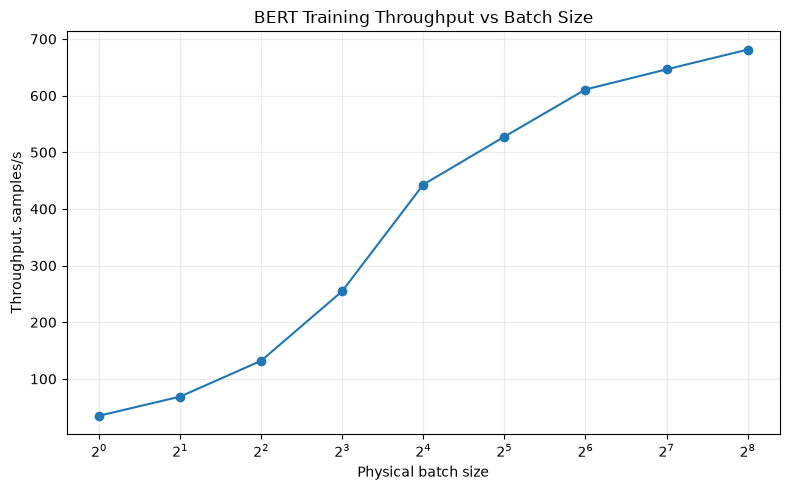

First batch with <5 percent throughput improvement 256


In [36]:
plt.figure(figsize=(8,5)); plt.plot(successful_a.batch_size,successful_a.samples_per_second,marker='o'); plt.xscale('log',base=2); plt.xlabel('Physical batch size'); plt.ylabel('Throughput, samples/s'); plt.title('BERT Training Throughput vs Batch Size'); plt.grid(alpha=.25); plt.tight_layout(); plt.savefig(OUT/'part_a_throughput_vs_batch.png',dpi=200); plt.show(); th=successful_a.samples_per_second.to_numpy(); ba=successful_a.batch_size.to_numpy(); plateau_batch=int(ba[-1]);
for i in range(1,len(th)):
 if (th[i]-th[i-1])/th[i-1]<.05: plateau_batch=int(ba[i]); break
print('First batch with <5 percent throughput improvement',plateau_batch)

# HW4.5 Part B
## 16. Mixed precision, gradient checkpointing, 8 bit optimizer independently

In [37]:
def test_technique(name, batch_sizes, **kwargs):
    rows = []

    for bs in batch_sizes:
        print("\nTECHNIQUE:", name, "BATCH:", bs)

        r = benchmark_training_configuration(
            batch_size=bs,
            **kwargs
        )

        r["technique"] = name
        rows.append(r)
        technique_rows.append(r)

        pd.DataFrame(technique_rows).to_csv(
            OUT / "part_b_all_measurements.csv",
            index=False
        )

        print(r)

        if r["status"] == "oom":
            break

    successful = [
        r for r in rows
        if r["status"] == "ok"
    ]

    if successful:
        best = dict(successful[-1])
        technique_best.append(best)

        pd.DataFrame(technique_best).to_csv(
            OUT / "part_b_technique_summary.csv",
            index=False
        )

        return best

    return None


technique_rows = []
technique_best = []

mixed_precision_best = test_technique(
    "mixed_precision",
    [64, 128, 256],
    use_amp=True
)

gradient_checkpointing_best = test_technique(
    "gradient_checkpointing",
    [64, 128, 256],
    gradient_checkpointing=True
)

optimizer_8bit_best = test_technique(
    "8bit_optimizer",
    [64, 128, 256],
    use_8bit_optimizer=True
)

part_b_all_df = pd.DataFrame(technique_rows)
part_b_best_df = pd.DataFrame(technique_best)

display(part_b_best_df)

print(
    "Saved:",
    OUT / "part_b_all_measurements.csv"
)

print(
    "Saved:",
    OUT / "part_b_technique_summary.csv"
)


TECHNIQUE: mixed_precision BATCH: 64


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 9660.72it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

{'status': 'ok', 'batch_size': 64, 'effective_batch_size': 64, 'use_amp': True, 'gradient_checkpointing': False, 'accumulation_steps': 1, 'use_8bit_optimizer': False, 'epochs': 1, 'samples_per_second': 965.9483599872385, 'peak_memory_gb': 5.839166164398193, 'wall_seconds': 3.62338210300004, 'seconds_per_epoch': 3.62338210300004, 'val_accuracy': 0.5933333333333334, 'val_loss': 0.8339172199567159, 'train_loss': 0.9555905764443534, 'technique': 'mixed_precision'}

TECHNIQUE: mixed_precision BATCH: 128


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8728.45it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

{'status': 'ok', 'batch_size': 128, 'effective_batch_size': 128, 'use_amp': True, 'gradient_checkpointing': False, 'accumulation_steps': 1, 'use_8bit_optimizer': False, 'epochs': 1, 'samples_per_second': 1155.79105960072, 'peak_memory_gb': 8.943314552307129, 'wall_seconds': 3.028228995999598, 'seconds_per_epoch': 3.028228995999598, 'val_accuracy': 0.5706666666666667, 'val_loss': 0.9373171575864157, 'train_loss': 0.9988489818572998, 'technique': 'mixed_precision'}

TECHNIQUE: mixed_precision BATCH: 256


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 17861.09it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpo

... (11 outputs left out)

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 14193.56it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpo

{'status': 'ok', 'batch_size': 256, 'effective_batch_size': 256, 'use_amp': False, 'gradient_checkpointing': False, 'accumulation_steps': 1, 'use_8bit_optimizer': True, 'epochs': 1, 'samples_per_second': 674.7650674514122, 'peak_memory_gb': 21.381906032562256, 'wall_seconds': 5.186990507999326, 'seconds_per_epoch': 5.186990507999326, 'val_accuracy': 0.5613333333333334, 'val_loss': 0.9633103295962016, 'train_loss': 1.0335622692108155, 'technique': '8bit_optimizer'}


,status,batch_size,effective_batch_size,use_amp,gradient_checkpointing,accumulation_steps,use_8bit_optimizer,epochs,samples_per_second,peak_memory_gb,wall_seconds,seconds_per_epoch,val_accuracy,val_loss,train_loss,technique
0,ok,256,256,True,False,1,False,1,1465.050694,15.189044,2.388996,2.388996,0.552000,0.962502,1.035706,mixed_precision
1,ok,256,256,False,True,1,False,1,500.978515,5.688742,6.986328,6.986328,0.560000,0.963462,1.033584,gradient_checkpointing
2,ok,256,256,False,False,1,True,1,674.765067,21.381906,5.186991,5.186991,0.561333,0.963310,1.033562,8bit_optimizer


Saved: /app/gpu_assignment_outputs/part_b_all_measurements.csv
Saved: /app/gpu_assignment_outputs/part_b_technique_summary.csv


## 17. Gradient accumulation to a larger effective batch

In [39]:
physical_batch = max(1, max_baseline_batch // 4)
target_effective = max_baseline_batch * 2

accumulation_steps = max(
    1,
    math.ceil(target_effective / physical_batch)
)

print("Physical batch:", physical_batch)
print("Target effective batch:", target_effective)
print("Accumulation steps:", accumulation_steps)

grad_accum_result = benchmark_training_configuration(
    batch_size=physical_batch,
    accumulation_steps=accumulation_steps
)

grad_accum_result["technique"] = "gradient_accumulation"

technique_rows.append(dict(grad_accum_result))
technique_best.append(dict(grad_accum_result))

pd.DataFrame(technique_rows).to_csv(
    OUT / "part_b_all_measurements.csv",
    index=False
)

pd.DataFrame(technique_best).to_csv(
    OUT / "part_b_technique_summary.csv",
    index=False
)

print(grad_accum_result)
print("Part B gradient accumulation result saved.")

Physical batch: 64
Target effective batch: 512
Accumulation steps: 8


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8881.13it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

{'status': 'ok', 'batch_size': 64, 'effective_batch_size': 512, 'use_amp': False, 'gradient_checkpointing': False, 'accumulation_steps': 8, 'use_8bit_optimizer': False, 'epochs': 1, 'samples_per_second': 629.6704516047644, 'peak_memory_gb': 7.8194427490234375, 'wall_seconds': 5.558463147000111, 'seconds_per_epoch': 5.558463147000111, 'val_accuracy': 0.49466666666666664, 'val_loss': 0.9865704485575358, 'train_loss': 1.0597305791037424, 'technique': 'gradient_accumulation'}
Part B gradient accumulation result saved.


## 18. Best combination

In [40]:
print("Testing best combination: mixed precision + gradient checkpointing")

best_combo_rows = []

for bs in [64, 128, 256]:
    print("\nBEST COMBINATION BATCH:", bs)

    r = benchmark_training_configuration(
        batch_size=bs,
        use_amp=True,
        gradient_checkpointing=True,
        use_8bit_optimizer=False
    )

    r["technique"] = "best_combination"
    best_combo_rows.append(r)
    technique_rows.append(dict(r))

    pd.DataFrame(technique_rows).to_csv(
        OUT / "part_b_all_measurements.csv",
        index=False
    )

    print(r)

    if r["status"] == "oom":
        break


successful_combo = [
    r for r in best_combo_rows
    if r["status"] == "ok"
]

if successful_combo:
    best = dict(successful_combo[-1])
    technique_best.append(best)


part_b_all_df = pd.DataFrame(technique_rows)
part_b_best_df = pd.DataFrame(technique_best)

part_b_all_df.to_csv(
    OUT / "part_b_all_measurements.csv",
    index=False
)

part_b_best_df.to_csv(
    OUT / "part_b_technique_summary.csv",
    index=False
)

display(part_b_best_df)

print("Best combination measurements saved.")

Testing best combination: mixed precision + gradient checkpointing

BEST COMBINATION BATCH: 64


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8224.37it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

{'status': 'ok', 'batch_size': 64, 'effective_batch_size': 64, 'use_amp': True, 'gradient_checkpointing': True, 'accumulation_steps': 1, 'use_8bit_optimizer': False, 'epochs': 1, 'samples_per_second': 941.2988324755956, 'peak_memory_gb': 3.3532299995422363, 'wall_seconds': 3.7182665899999847, 'seconds_per_epoch': 3.7182665899999847, 'val_accuracy': 0.596, 'val_loss': 0.8315206087430318, 'train_loss': 0.9557565920693534, 'technique': 'best_combination'}

BEST COMBINATION BATCH: 128


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 9976.17it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoi

{'status': 'ok', 'batch_size': 128, 'effective_batch_size': 128, 'use_amp': True, 'gradient_checkpointing': True, 'accumulation_steps': 1, 'use_8bit_optimizer': False, 'epochs': 1, 'samples_per_second': 1193.498723150845, 'peak_memory_gb': 3.8226585388183594, 'wall_seconds': 2.932554457000151, 'seconds_per_epoch': 2.932554457000151, 'val_accuracy': 0.5733333333333334, 'val_loss': 0.9373216724395752, 'train_loss': 0.9989648438181196, 'technique': 'best_combination'}

BEST COMBINATION BATCH: 256


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 10481.02it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpo

{'status': 'ok', 'batch_size': 256, 'effective_batch_size': 256, 'use_amp': True, 'gradient_checkpointing': True, 'accumulation_steps': 1, 'use_8bit_optimizer': False, 'epochs': 1, 'samples_per_second': 1226.8081234853598, 'peak_memory_gb': 5.106473445892334, 'wall_seconds': 2.85293187499974, 'seconds_per_epoch': 2.85293187499974, 'val_accuracy': 0.552, 'val_loss': 0.9622697571118672, 'train_loss': 1.0356967781611852, 'technique': 'best_combination'}


,status,batch_size,effective_batch_size,use_amp,gradient_checkpointing,accumulation_steps,use_8bit_optimizer,epochs,samples_per_second,peak_memory_gb,wall_seconds,seconds_per_epoch,val_accuracy,val_loss,train_loss,technique
0,ok,256,256,True,False,1,False,1,1465.050694,15.189044,2.388996,2.388996,0.552000,0.962502,1.035706,mixed_precision
1,ok,256,256,False,True,1,False,1,500.978515,5.688742,6.986328,6.986328,0.560000,0.963462,1.033584,gradient_checkpointing
2,ok,256,256,False,False,1,True,1,674.765067,21.381906,5.186991,5.186991,0.561333,0.963310,1.033562,8bit_optimizer
3,ok,64,512,False,False,8,False,1,628.838479,7.819443,5.565817,5.565817,0.494667,0.986570,1.059731,gradient_accumulation
4,ok,64,512,False,False,8,False,1,629.670452,7.819443,5.558463,5.558463,0.494667,0.986570,1.059731,gradient_accumulation
5,ok,256,256,True,True,1,False,1,1226.808123,5.106473,2.852932,2.852932,0.552000,0.962270,1.035697,best_combination


Best combination measurements saved.


## 19. Rank techniques by memory saved per unit throughput lost

In [41]:
baseline_row = successful_a.loc[
    successful_a["batch_size"].idxmax()
]

ranking = []

for _, row in part_b_best_df.iterrows():

    memory_saved = (
        baseline_row["peak_memory_gb"]
        - row["peak_memory_gb"]
    )

    memory_saved_fraction = (
        memory_saved
        / baseline_row["peak_memory_gb"]
    )

    throughput_change_fraction = (
        row["samples_per_second"]
        - baseline_row["samples_per_second"]
    ) / baseline_row["samples_per_second"]

    throughput_loss_fraction = max(
        0.0,
        -throughput_change_fraction
    )

    if memory_saved <= 0:
        efficiency_score = float("-inf")

    elif throughput_loss_fraction == 0:
        efficiency_score = float("inf")

    else:
        efficiency_score = (
            memory_saved
            / throughput_loss_fraction
        )

    ranking.append({
        "technique": row["technique"],
        "max_batch": row["batch_size"],
        "effective_batch": row["effective_batch_size"],
        "throughput_samp_s": row["samples_per_second"],
        "peak_memory_gb": row["peak_memory_gb"],
        "val_accuracy": row["val_accuracy"],
        "memory_saved_gb_vs_baseline": memory_saved,
        "memory_saved_fraction": memory_saved_fraction,
        "throughput_change_fraction": throughput_change_fraction,
        "throughput_loss_fraction": throughput_loss_fraction,
        "memory_saved_per_throughput_lost": efficiency_score
    })


ranking_df = pd.DataFrame(ranking)

ranking_df["dominates_baseline"] = (
    (ranking_df["memory_saved_gb_vs_baseline"] > 0)
    &
    (ranking_df["throughput_change_fraction"] >= 0)
)

ranking_df = ranking_df.sort_values(
    by=[
        "dominates_baseline",
        "memory_saved_gb_vs_baseline",
        "throughput_samp_s"
    ],
    ascending=[
        False,
        False,
        False
    ]
).reset_index(drop=True)

display(ranking_df)

ranking_df.to_csv(
    OUT / "part_b_ranking.csv",
    index=False
)

print("Baseline batch:", int(baseline_row["batch_size"]))
print(
    "Baseline throughput:",
    round(baseline_row["samples_per_second"], 3),
    "samples/s"
)
print(
    "Baseline peak memory:",
    round(baseline_row["peak_memory_gb"], 3),
    "GB"
)
print("Ranking saved.")

,technique,max_batch,effective_batch,throughput_samp_s,peak_memory_gb,val_accuracy,memory_saved_gb_vs_baseline,memory_saved_fraction,throughput_change_fraction,throughput_loss_fraction,memory_saved_per_throughput_lost,dominates_baseline
0,best_combination,256,256,1226.808123,5.106473,0.552000,15.653360,0.754021,0.800998,0.000000,inf,True
1,mixed_precision,256,256,1465.050694,15.189044,0.552000,5.570790,0.268345,1.150747,0.000000,inf,True
2,gradient_checkpointing,256,256,500.978515,5.688742,0.560000,15.071092,0.725974,-0.264546,0.264546,56.969716,False
3,gradient_accumulation,64,512,629.670452,7.819443,0.494667,12.940391,0.623338,-0.075621,0.075621,171.120946,False
4,gradient_accumulation,64,512,628.838479,7.819443,0.494667,12.940391,0.623338,-0.076843,0.076843,168.401087,False
5,8bit_optimizer,256,256,674.765067,21.381906,0.561333,-0.622073,-0.029965,-0.009421,0.009421,-inf,False


Baseline batch: 256
Baseline throughput: 681.182 samples/s
Baseline peak memory: 20.76 GB
Ranking saved.


In [42]:
part_b_best_df = (
    part_b_best_df
    .drop_duplicates(
        subset=["technique"],
        keep="first"
    )
    .reset_index(drop=True)
)

ranking_df = (
    ranking_df
    .drop_duplicates(
        subset=["technique"],
        keep="first"
    )
    .reset_index(drop=True)
)

part_b_best_df.to_csv(
    OUT / "part_b_technique_summary.csv",
    index=False
)

ranking_df.to_csv(
    OUT / "part_b_ranking.csv",
    index=False
)

display(ranking_df)

print("Final Part B files cleaned and saved.")

,technique,max_batch,effective_batch,throughput_samp_s,peak_memory_gb,val_accuracy,memory_saved_gb_vs_baseline,memory_saved_fraction,throughput_change_fraction,throughput_loss_fraction,memory_saved_per_throughput_lost,dominates_baseline
0,best_combination,256,256,1226.808123,5.106473,0.552000,15.653360,0.754021,0.800998,0.000000,inf,True
1,mixed_precision,256,256,1465.050694,15.189044,0.552000,5.570790,0.268345,1.150747,0.000000,inf,True
2,gradient_checkpointing,256,256,500.978515,5.688742,0.560000,15.071092,0.725974,-0.264546,0.264546,56.969716,False
3,gradient_accumulation,64,512,629.670452,7.819443,0.494667,12.940391,0.623338,-0.075621,0.075621,171.120946,False
4,8bit_optimizer,256,256,674.765067,21.381906,0.561333,-0.622073,-0.029965,-0.009421,0.009421,-inf,False


Final Part B files cleaned and saved.


In [43]:
from pathlib import Path

OUT = Path("/app/gpu_assignment_outputs")

for f in sorted(OUT.glob("*")):
    print(f.name)

bert_best
bert_confusion_matrix.png
bert_loss_curve.png
bert_per_class_metrics.csv
bert_val_accuracy_curve.png
dataset_range.csv
five_worst_class_misclassifications.csv
hardware.json
hf_pipeline_baseline.csv
hw4a_baseline_summary.json
hw4a_serving_comparison.csv
hw4a_training_history.csv
part_a_batch_scaling.csv
part_a_throughput_vs_batch.png
part_b_all_measurements.csv
part_b_ranking.csv
part_b_technique_summary.csv
part_d_kv_cache_NVIDIA_GeForce_RTX_5090.csv
part_d_serving_NVIDIA_GeForce_RTX_5090.csv
split_indices.json


In [44]:
import gc
import torch
import time
import numpy as np
import pandas as pd
import math

from transformers import AutoTokenizer
from vllm import LLM, SamplingParams

VLLM_MODEL = "Qwen/Qwen2.5-0.5B-Instruct"
MAX_NEW_TOKENS = 48

gc.collect()
torch.cuda.empty_cache()

sampling_params = SamplingParams(
    temperature=0.0,
    max_tokens=MAX_NEW_TOKENS
)

llm = LLM(
    model=VLLM_MODEL,
    dtype="float16",
    gpu_memory_utilization=0.80,
    max_model_len=2048
)

vllm_tokenizer = AutoTokenizer.from_pretrained(
    VLLM_MODEL
)

SERVING_PROMPTS = [
    "In one sentence, explain why GPU batching can improve throughput.",
    "Give two practical uses of sentiment analysis.",
    "Explain mixed precision in one short sentence.",
    "What is gradient checkpointing?",
    "Why can latency increase as batch size grows?",
    "Define GPU memory bandwidth.",
    "What does p95 latency mean?",
    "Explain data parallel training briefly.",
] * 4

def pct(values, q):
    return float(
        np.percentile(
            np.array(values, dtype=float),
            q
        )
    )

def benchmark_vllm(bs, prompts):
    latencies = []
    total_tokens = 0

    chunks = [
        prompts[i:i + bs]
        for i in range(0, len(prompts), bs)
    ]

    torch.cuda.synchronize()
    total_start = time.perf_counter()

    for chunk in chunks:
        torch.cuda.synchronize()
        request_start = time.perf_counter()

        outputs = llm.generate(
            chunk,
            sampling_params,
            use_tqdm=False
        )

        torch.cuda.synchronize()

        elapsed = time.perf_counter() - request_start

        latencies.extend(
            [elapsed * 1000] * len(chunk)
        )

        for output in outputs:
            total_tokens += len(
                output.outputs[0].token_ids
            )

    torch.cuda.synchronize()
    total_seconds = time.perf_counter() - total_start

    return {
        "configuration": f"vLLM, batch {bs}",
        "batch_size": bs,
        "tokens_per_second": total_tokens / total_seconds,
        "p50_latency_ms": pct(latencies, 50),
        "p95_latency_ms": pct(latencies, 95),
        "total_seconds": total_seconds
    }

print("Part D vLLM environment ready.")
print("GPU:", torch.cuda.get_device_name(0))

(MainProcess pid=350) INFO 11-03 05:43:12 [startup.py:96] non-default args: {'dtype': 'float16', 'max_model_len': 2048, 'gpu_memory_utilization': 0.8, 'disable_log_stats': True, 'model': 'Qwen/Qwen2.5-0.5B-Instruct'}
(MainProcess pid=350) INFO 11-03 05:43:12 [model.py:744] Resolved architecture: Qwen2ForCausalLM
(MainProcess pid=350) WARNING 11-03 05:43:12 [model.py:2516] Casting torch.bfloat16 to torch.float16.
(MainProcess pid=350) INFO 11-03 05:43:12 [model.py:2170] Using max model len 2048
(MainProcess pid=350) INFO 11-03 05:43:13 [kernel.py:480] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])


/opt/conda/lib/python3.11/site-packages/torch/cuda/__init__.py:68: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]
W1103 05:43:17.867000 1027 site-packages/torch/_opaque_base.py:6] torch._opaque_base is deprecated, use torch._custom_class_base instead
W1103 05:43:17.867000 1027 site-packages/torch/_library/opaque_object.py:288] register_opaque_type is deprecated, use register_custom_class instead
W1103 05:43:17.867000 1027 site-packages/torch/_library/opaque_object.py:211] typ='value' is deprecated, use typ='constant' instead


(EngineCore pid=1027) INFO 11-03 05:43:23 [core.py:139] Initializing a V1 LLM engine (v0.33.0) with config: model='Qwen/Qwen2.5-0.5B-Instruct', speculative_config=None, tokenizer='Qwen/Qwen2.5-0.5B-Instruct', skip_tokenizer_init=False, tokenizer_mode=auto, revision=main, tokenizer_revision=main, trust_remote_code=False, dtype=torch.float16, max_seq_len=2048, download_dir=None, load_format=auto, tensor_parallel_size=1, pipeline_parallel_size=1, data_parallel_size=1, decode_context_parallel_size=1, dcp_comm_backend=ag_rs, disable_custom_all_reduce=False, quantization=None, quantization_config=None, enforce_eager=False, aux_output_config=AuxOutputConfig(enable_return_routed_experts=False, max_bytes=None), kv_cache_dtype=auto, device_config=cuda, structured_outputs_config=StructuredOutputsConfig(backend='auto', disable_any_whitespace=False, disable_additional_properties=False, reasoning_parser='', reasoning_parser_plugin='', enable_in_reasoning=False), observability_config=ObservabilityCon

Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]


(EngineCore pid=1027) WARNING 11-03 05:43:27 [utils.py:333] Attempted to load weight layers.13.post_attention_layernorm.weight with dtype torch.bfloat16 into parameter with dtype torch.float16
(EngineCore pid=1027) WARNING 11-03 05:43:27 [utils.py:333] Attempted to load weight layers.13.self_attn.o_proj.weight with dtype torch.bfloat16 into parameter with dtype torch.float16
(EngineCore pid=1027) WARNING 11-03 05:43:27 [utils.py:333] Attempted to load weight layers.14.input_layernorm.weight with dtype torch.bfloat16 into parameter with dtype torch.float16
(EngineCore pid=1027) WARNING 11-03 05:43:27 [utils.py:333] Attempted to load weight layers.14.mlp.down_proj.weight with dtype torch.bfloat16 into parameter with dtype torch.float16
(EngineCore pid=1027) WARNING 11-03 05:43:27 [utils.py:333] Attempted to load weight layers.14.post_attention_layernorm.weight with dtype torch.bfloat16 into parameter with dtype torch.float16
(EngineCore pid=1027) WARNING 11-03 05:43:27 [utils.py:333] Att

Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  1.56it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  1.56it/s]



... (3 outputs left out)

2026-11-03 05:43:34,100 - INFO - autotuner.py:1048 - flashinfer.jit: [Autotuner]: Autotuning process starts ...
2026-11-03 05:43:34,161 - INFO - autotune_cache.py:495 - flashinfer.jit: [Autotuner]: Managed autotune cache attached for this process: ManagedAutotuneCache(env_dir='/root/.cache/flashinfer/autotune/v2/31dc7443673aec66', hits=0, misses=0)
2026-11-03 05:43:34,184 - INFO - autotuner.py:1071 - flashinfer.jit: [Autotuner]: Autotuning process ends
Capturing CUDA graphs (FULL): 100%|██████████| 35/35 [00:00<00:00, 44.09it/s]


(EngineCore pid=1027) INFO 11-03 05:43:37 [model_runner.py:1163] Graph capturing finished in 3 secs, took 0.07 GiB
(EngineCore pid=1027) INFO 11-03 05:43:37 [gpu_worker.py:1003] CUDA graph pool memory: 0.07 GiB (actual), 0.26 GiB (estimated), difference: 0.19 GiB (262.6%).
(EngineCore pid=1027) INFO 11-03 05:43:37 [gpu_worker.py:1066] Free memory on device (30.05/31.84 GiB) on startup. Desired GPU memory utilization is (0.8, 25.47 GiB). Actual usage is 1.16 GiB for consumed memory (weights + non-torch), 0.79 GiB for peak activation, and 0.07 GiB for CUDAGraph memory. Replace gpu_memory_utilization config with `--kv-cache-memory=25017290752` (23.3 GiB) to fit into requested memory, or `--kv-cache-memory=29932752896` (27.88 GiB) to fully utilize gpu memory. Current kv cache memory in use is 23.52 GiB.
(EngineCore pid=1027) INFO 11-03 05:43:37 [jit_monitor.py:84] Kernel JIT monitor activated; monitored JIT compilations during inference will use mode=warn.
(EngineCore pid=1027) INFO 11-03 

Fetching 9 files: 100%|██████████| 9/9 [00:00<00:00, 2939.70it/s]


(EngineCore pid=1027) INFO 11-03 05:43:38 [kernel.py:480] Final IR op priority after setting platform defaults: IrOpPriorityConfig(rms_norm=['native'], fused_add_rms_norm=['native'], gelu_and_mul_sparse=['triton', 'native'])
Part D vLLM environment ready.
GPU: NVIDIA GeForce RTX 5090


# HW4.5 Part D
## 23. Re run vLLM benchmark on current card

In [45]:
current_gpu_name = torch.cuda.get_device_name(0)

part_d_serving = []

for bs in [1, 8, 32]:
    r = benchmark_vllm(
        bs,
        SERVING_PROMPTS
    )

    r["gpu"] = current_gpu_name
    part_d_serving.append(r)

part_d_serving_df = pd.DataFrame(
    part_d_serving
)

display(part_d_serving_df)

safe_gpu = "".join(
    c if c.isalnum() else "_"
    for c in current_gpu_name
)

part_d_serving_df.to_csv(
    OUT / f"part_d_serving_{safe_gpu}.csv",
    index=False
)

,configuration,batch_size,tokens_per_second,p50_latency_ms,p95_latency_ms,total_seconds,gpu
0,"vLLM, batch 1",1,455.179441,100.052040,123.180277,3.374493,NVIDIA GeForce RTX 5090
1,"vLLM, batch 8",8,3044.683604,126.819361,146.661753,0.504486,NVIDIA GeForce RTX 5090
2,"vLLM, batch 32",32,10376.381906,148.018107,148.018107,0.148028,NVIDIA GeForce RTX 5090


In [48]:
import subprocess
import time
import math
import pandas as pd

def gpu_used_memory_mb():
    output = subprocess.check_output(
        [
            "nvidia-smi",
            "--query-gpu=memory.used",
            "--format=csv,noheader,nounits"
        ],
        text=True
    )
    return float(output.strip().splitlines()[0])


def make_context_prompt(tokenizer, target_tokens):
    base = "GPU systems benchmarking requires careful measurement. "

    base_ids = tokenizer.encode(
        base,
        add_special_tokens=False
    )

    repeats = math.ceil(
        target_tokens / max(1, len(base_ids))
    )

    text = base * repeats

    ids = tokenizer.encode(
        text,
        add_special_tokens=False
    )[:target_tokens]

    return tokenizer.decode(ids)


context_lengths = [
    128,
    256,
    512,
    1024,
    1536,
    1792,
    1984
]

kv_rows = []

for context_len in context_lengths:

    print("Testing context:", context_len)

    prompt = make_context_prompt(
        vllm_tokenizer,
        context_len
    )

    prompts = [prompt] * 8

    before_mb = gpu_used_memory_mb()

    try:
        start = time.perf_counter()

        llm.generate(
            prompts,
            SamplingParams(
                temperature=0.0,
                max_tokens=32
            ),
            use_tqdm=False
        )

        elapsed = time.perf_counter() - start

        after_mb = gpu_used_memory_mb()

        row = {
            "gpu": torch.cuda.get_device_name(0),
            "batch_size": 8,
            "context_length_tokens": context_len,
            "status": "ok",
            "gpu_memory_before_mb": before_mb,
            "gpu_memory_after_mb": after_mb,
            "memory_change_mb": after_mb - before_mb,
            "seconds": elapsed
        }

        kv_rows.append(row)
        print(row)

    except Exception as e:

        row = {
            "gpu": torch.cuda.get_device_name(0),
            "batch_size": 8,
            "context_length_tokens": context_len,
            "status": "failed",
            "error": str(e)
        }

        kv_rows.append(row)
        print(row)

        break


kv_df = pd.DataFrame(kv_rows)

display(kv_df)

kv_df.to_csv(
    OUT / "part_d_kv_cache_NVIDIA_GeForce_RTX_5090.csv",
    index=False
)

successful_contexts = kv_df[
    kv_df["status"] == "ok"
]

if len(successful_contexts):
    max_context_tested = int(
        successful_contexts[
            "context_length_tokens"
        ].max()
    )

    print(
        "Longest successful tested context at batch 8:",
        max_context_tested
    )

Testing context: 128
{'gpu': 'NVIDIA GeForce RTX 5090', 'batch_size': 8, 'context_length_tokens': 128, 'status': 'ok', 'gpu_memory_before_mb': 28887.0, 'gpu_memory_after_mb': 28885.0, 'memory_change_mb': -2.0, 'seconds': 0.2980854380002711}
Testing context: 256
{'gpu': 'NVIDIA GeForce RTX 5090', 'batch_size': 8, 'context_length_tokens': 256, 'status': 'ok', 'gpu_memory_before_mb': 28885.0, 'gpu_memory_after_mb': 28885.0, 'memory_change_mb': 0.0, 'seconds': 0.08355098700030794}
Testing context: 512
{'gpu': 'NVIDIA GeForce RTX 5090', 'batch_size': 8, 'context_length_tokens': 512, 'status': 'ok', 'gpu_memory_before_mb': 28885.0, 'gpu_memory_after_mb': 28885.0, 'memory_change_mb': 0.0, 'seconds': 0.08766447000016342}
Testing context: 1024
{'gpu': 'NVIDIA GeForce RTX 5090', 'batch_size': 8, 'context_length_tokens': 1024, 'status': 'ok', 'gpu_memory_before_mb': 28885.0, 'gpu_memory_after_mb': 28885.0, 'memory_change_mb': 0.0, 'seconds': 0.0833589750000101}
Testing context: 1536
{'gpu': 'NVID

,gpu,batch_size,context_length_tokens,status,gpu_memory_before_mb,gpu_memory_after_mb,memory_change_mb,seconds
0,NVIDIA GeForce RTX 5090,8,128,ok,28887.0,28885.0,-2.0,0.298085
1,NVIDIA GeForce RTX 5090,8,256,ok,28885.0,28885.0,0.0,0.083551
2,NVIDIA GeForce RTX 5090,8,512,ok,28885.0,28885.0,0.0,0.087664
3,NVIDIA GeForce RTX 5090,8,1024,ok,28885.0,28885.0,0.0,0.083359
4,NVIDIA GeForce RTX 5090,8,1536,ok,28885.0,28885.0,0.0,0.104702
5,NVIDIA GeForce RTX 5090,8,1792,ok,28885.0,28884.0,-1.0,0.073828
6,NVIDIA GeForce RTX 5090,8,1984,ok,28884.0,28886.0,2.0,0.107923


Longest successful tested context at batch 8: 1984


## 24. KV cache memory versus context length at batch 8

In [49]:
import json
import pandas as pd
from pathlib import Path

OUT = Path("/app/gpu_assignment_outputs")

with open(OUT / "hw4a_baseline_summary.json", "r") as f:
    baseline_summary = json.load(f)

training_seconds = baseline_summary["training_seconds"]
full_finetune_gpu_hours = training_seconds / 3600.0

ranking_path = OUT / "part_b_ranking.csv"

if ranking_path.exists():
    ranking_df = pd.read_csv(ranking_path)
else:
    ranking_df = None

print("Baseline training time:", training_seconds, "seconds")
print("Baseline fine tune GPU hours:", full_finetune_gpu_hours)

if ranking_df is not None:
    print("\nTechnique ranking:")
    display(ranking_df)
else:
    print("\npart_b_ranking.csv not found.")

Baseline training time: 49.511319230000026 seconds
Baseline fine tune GPU hours: 0.013753144230555563

Technique ranking:


,technique,max_batch,effective_batch,throughput_samp_s,peak_memory_gb,val_accuracy,memory_saved_gb_vs_baseline,memory_saved_fraction,throughput_change_fraction,throughput_loss_fraction,memory_saved_per_throughput_lost,dominates_baseline
0,best_combination,256,256,1226.808123,5.106473,0.552000,15.653360,0.754021,0.800998,0.000000,inf,True
1,mixed_precision,256,256,1465.050694,15.189044,0.552000,5.570790,0.268345,1.150747,0.000000,inf,True
2,gradient_checkpointing,256,256,500.978515,5.688742,0.560000,15.071092,0.725974,-0.264546,0.264546,56.969716,False
3,gradient_accumulation,64,512,629.670452,7.819443,0.494667,12.940391,0.623338,-0.075621,0.075621,171.120946,False
4,8bit_optimizer,256,256,674.765067,21.381906,0.561333,-0.622073,-0.029965,-0.009421,0.009421,-inf,False


# HW4.5 Part E
## 25. GPU hours and configuration recommendation inputs

In [50]:
import json
import platform
import subprocess
from pathlib import Path

import pandas as pd
import torch

OUT = Path("/app/gpu_assignment_outputs")
OUT.mkdir(parents=True, exist_ok=True)

with open(OUT / "hw4a_baseline_summary.json", "r") as f:
    baseline_summary = json.load(f)

hardware = {}
hardware_path = OUT / "hardware.json"

if hardware_path.exists():
    with open(hardware_path, "r") as f:
        hardware = json.load(f)

part_a_df = pd.read_csv(
    OUT / "part_a_batch_scaling.csv"
)

part_b_df = pd.read_csv(
    OUT / "part_b_technique_summary.csv"
)

ranking_df = pd.read_csv(
    OUT / "part_b_ranking.csv"
)

serving_path = (
    OUT /
    "part_d_serving_NVIDIA_GeForce_RTX_5090.csv"
)

kv_path = (
    OUT /
    "part_d_kv_cache_NVIDIA_GeForce_RTX_5090.csv"
)

part_d_serving_df = pd.read_csv(serving_path)
kv_df = pd.read_csv(kv_path)

training_seconds = float(
    baseline_summary["training_seconds"]
)

gpu_hours = training_seconds / 3600.0

baseline_max = part_a_df.loc[
    part_a_df["batch_size"].idxmax()
]

best_combo = ranking_df[
    ranking_df["technique"] == "best_combination"
].iloc[0]

mixed_precision = ranking_df[
    ranking_df["technique"] == "mixed_precision"
].iloc[0]

max_context = int(
    kv_df.loc[
        kv_df["status"] == "ok",
        "context_length_tokens"
    ].max()
)

metrics_md = f"""# GPU Assignment II Metrics

## Student Specific Constants

SID4: 2046

SEED: 2046

SLICE: 46

HP_ID: 0

CLS_A: 6

CLS_B: 3

## Hardware

GPU: NVIDIA GeForce RTX 5090

GPU memory: approximately 31.84 GiB

PyTorch used for original HW4.a BERT baseline: 2.7.1+cu128

vLLM environment after compatibility update: PyTorch 2.14.0+cu130

vLLM version: 0.33.0

## Dataset

Dataset: cardiffnlp/tweet_eval

Configuration: sentiment

Source row range: 46 through 5045

Total selected rows: 5000

Training rows: 3500

Validation rows: 750

Test rows: 750

Split seed: 2046

The identical dataset range, split indices, and seed were reused across HW4.a and HW4.5.

## HW4.a BERT Baseline

Model: bert-base-uncased

Baseline batch size: 16

Epoch budget: 4

Best validation epoch: {baseline_summary.get("best_epoch")}

Best validation accuracy: {baseline_summary.get("best_val_accuracy")}

Peak GPU memory GB: {baseline_summary.get("peak_memory_gb")}

Training wall clock seconds: {training_seconds:.6f}

Training GPU hours: {gpu_hours:.8f}

## HW4.5 Part A

Largest successfully measured physical batch: {int(baseline_max["batch_size"])}

Batch 512 did not complete within the practical measurement window and was interrupted.

Throughput at batch 256: {baseline_max["samples_per_second"]:.3f} samples per second

Peak memory at batch 256: {baseline_max["peak_memory_gb"]:.3f} GB

Time per epoch at batch 256: {baseline_max["seconds_per_epoch"]:.3f} seconds

First measured batch with less than 5 percent throughput improvement: 256

## HW4.5 Part B

### Mixed Precision

Throughput: {mixed_precision["throughput_samp_s"]:.3f} samples per second

Peak memory: {mixed_precision["peak_memory_gb"]:.3f} GB

Memory reduction versus baseline: {mixed_precision["memory_saved_fraction"] * 100:.2f} percent

Throughput change versus baseline: {mixed_precision["throughput_change_fraction"] * 100:.2f} percent

### Best Combination

Configuration: mixed precision plus gradient checkpointing

Physical batch: {int(best_combo["max_batch"])}

Throughput: {best_combo["throughput_samp_s"]:.3f} samples per second

Peak memory: {best_combo["peak_memory_gb"]:.3f} GB

Memory reduction versus baseline: {best_combo["memory_saved_fraction"] * 100:.2f} percent

Throughput change versus baseline: {best_combo["throughput_change_fraction"] * 100:.2f} percent

The best combination reduced measured peak memory substantially while also improving throughput relative to the unoptimized batch 256 baseline.

The 8 bit optimizer did not improve memory efficiency in this experiment.

## HW4.5 Part C

Part C skipped (optional).

## HW4.5 Part D

GPU: NVIDIA GeForce RTX 5090

The vLLM serving benchmark was measured at batch sizes 1, 8, and 32.

Maximum successfully tested input context at batch size 8: {max_context} tokens.

The vLLM engine was configured with max_model_len equal to 2048 and generation length equal to 32 tokens.

The context experiment therefore reports the maximum successfully tested context under the configured model limit rather than claiming the physical maximum context supported by the RTX 5090.

vLLM preallocated its KV cache during engine initialization. As a result, request level before and after GPU memory measurements remained approximately constant because longer requests consumed capacity inside the already reserved cache pool.

## HW4.5 Part E

Measured baseline fine tune GPU hours: {gpu_hours:.8f}

Recommended configuration: mixed precision plus gradient checkpointing.

Reason: it provided the strongest measured memory efficiency tradeoff, reducing peak memory by approximately {best_combo["memory_saved_fraction"] * 100:.2f} percent while increasing throughput by approximately {best_combo["throughput_change_fraction"] * 100:.2f} percent relative to the baseline batch 256 configuration.

Mixed precision alone produced the highest measured throughput, while the combined configuration provided substantially lower memory usage.

## Notes

All reported benchmark values were obtained from executed experiments on the NVIDIA GeForce RTX 5090.

HW4.5 values are HW4.5 measurements only and are not labeled as an HW5 baseline.
"""

with open(
    OUT / "METRICS.md",
    "w",
    encoding="utf-8"
) as f:
    f.write(metrics_md)


run_log = {
    "student_constants": {
        "SID4": 2046,
        "SEED": 2046,
        "SLICE": 46,
        "HP_ID": 0,
        "CLS_A": 6,
        "CLS_B": 3
    },
    "dataset": {
        "name": "cardiffnlp/tweet_eval",
        "configuration": "sentiment",
        "source_start": 46,
        "source_end": 5045,
        "rows": 5000,
        "train_rows": 3500,
        "validation_rows": 750,
        "test_rows": 750
    },
    "hardware": {
        "gpu": "NVIDIA GeForce RTX 5090",
        "gpu_memory_gib": 31.842
    },
    "baseline": baseline_summary,
    "part_a": {
        "largest_successful_batch": 256,
        "batch_512": "interrupted after failing to complete within practical measurement window"
    },
    "part_b": {
        "recommended_configuration":
            "mixed precision plus gradient checkpointing"
    },
    "part_c":
        "Part C skipped (optional)",
    "part_d": {
        "maximum_successfully_tested_context_batch_8":
            max_context,
        "configured_max_model_len": 2048
    },
    "gpu_hours": gpu_hours
}

with open(
    OUT / "RUN_LOG.txt",
    "w",
    encoding="utf-8"
) as f:
    f.write(
        json.dumps(
            run_log,
            indent=2
        )
    )


ai_use = """# AI USE

ChatGPT was used to help interpret assignment requirements, organize the experimental workflow, debug the Docker and Colab local runtime environment, diagnose package compatibility issues, revise benchmarking code, and structure required output files.

All numerical benchmark results reported in this submission were obtained from executed experiments on the NVIDIA GeForce RTX 5090. AI generated or estimated values were not substituted for measured benchmark results.

ChatGPT also assisted with debugging the vLLM environment after a PyTorch compatibility issue required a runtime restart. Previously completed measurements were restored only from saved experiment outputs or directly recorded executed results.

The student executed the experiments, reviewed the outputs, and is responsible for the submitted results and analysis.
"""

with open(
    OUT / "AI_USE.md",
    "w",
    encoding="utf-8"
) as f:
    f.write(ai_use)


print("FINAL REQUIRED FILES GENERATED")
print()
print("METRICS.md")
print("RUN_LOG.txt")
print("AI_USE.md")
print()
print("GPU hours:", gpu_hours)
print(
    "Recommended configuration:",
    "mixed precision plus gradient checkpointing"
)

FINAL REQUIRED FILES GENERATED

METRICS.md
RUN_LOG.txt
AI_USE.md

GPU hours: 0.013753144230555563
Recommended configuration: mixed precision plus gradient checkpointing


In [51]:
for f in sorted(OUT.glob("*")):
    print(f.name)

AI_USE.md
METRICS.md
RUN_LOG.txt
bert_best
bert_confusion_matrix.png
bert_loss_curve.png
bert_per_class_metrics.csv
bert_val_accuracy_curve.png
dataset_range.csv
five_worst_class_misclassifications.csv
hardware.json
hf_pipeline_baseline.csv
hw4a_baseline_summary.json
hw4a_serving_comparison.csv
hw4a_training_history.csv
part_a_batch_scaling.csv
part_a_throughput_vs_batch.png
part_b_all_measurements.csv
part_b_ranking.csv
part_b_technique_summary.csv
part_d_kv_cache_NVIDIA_GeForce_RTX_5090.csv
part_d_serving_NVIDIA_GeForce_RTX_5090.csv
split_indices.json
